# Digit 8

#Starter Code

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn import datasets

# Load dataset
digits = datasets.load_digits()

# Create feature column names (pixel_0 to pixel_63)
feature_names = [f'pixel_{i}' for i in range(digits.data.shape[1])]

# Create DataFrame
df = pd.DataFrame(digits.data, columns=feature_names)

# Add target column
df['digit'] = digits.target

# Preview
print(df.head())

# Check shape
print("Shape:", df.shape)

   pixel_0  pixel_1  pixel_2  pixel_3  pixel_4  pixel_5  pixel_6  pixel_7  \
0      0.0      0.0      5.0     13.0      9.0      1.0      0.0      0.0   
1      0.0      0.0      0.0     12.0     13.0      5.0      0.0      0.0   
2      0.0      0.0      0.0      4.0     15.0     12.0      0.0      0.0   
3      0.0      0.0      7.0     15.0     13.0      1.0      0.0      0.0   
4      0.0      0.0      0.0      1.0     11.0      0.0      0.0      0.0   

   pixel_8  pixel_9  ...  pixel_55  pixel_56  pixel_57  pixel_58  pixel_59  \
0      0.0      0.0  ...       0.0       0.0       0.0       6.0      13.0   
1      0.0      0.0  ...       0.0       0.0       0.0       0.0      11.0   
2      0.0      0.0  ...       0.0       0.0       0.0       0.0       3.0   
3      0.0      8.0  ...       0.0       0.0       0.0       7.0      13.0   
4      0.0      0.0  ...       0.0       0.0       0.0       0.0       2.0   

   pixel_60  pixel_61  pixel_62  pixel_63  digit  
0      10.0      

#Filtering for Digit 8

In [ ]:
# Filter only digit 8
df_8 = df[df['digit'] == 8].copy()

# Reset index (optional but recommended)
df_8.reset_index(drop=True, inplace=True)

# Check shape
print("Shape of digit 8 subset:", df_8.shape)

# Preview
print(df_8.head())
print(df_8['digit'].unique())

Shape of digit 8 subset: (174, 65)
   pixel_0  pixel_1  pixel_2  pixel_3  pixel_4  pixel_5  pixel_6  pixel_7  \
0      0.0      0.0      9.0     14.0      8.0      1.0      0.0      0.0   
1      0.0      0.0     10.0      7.0     13.0      9.0      0.0      0.0   
2      0.0      0.0     10.0     11.0      4.0      0.0      0.0      0.0   
3      0.0      0.0      7.0      7.0     13.0     16.0      4.0      0.0   
4      0.0      0.0     11.0     10.0     12.0      4.0      0.0      0.0   

   pixel_8  pixel_9  ...  pixel_55  pixel_56  pixel_57  pixel_58  pixel_59  \
0      0.0      0.0  ...       0.0       0.0       0.0      11.0      16.0   
1      0.0      0.0  ...       0.0       0.0       0.0      11.0      14.0   
2      0.0      0.0  ...       0.0       0.0       0.0       8.0      14.0   
3      0.0      0.0  ...       0.0       0.0       1.0      11.0      16.0   
4      0.0      0.0  ...       0.0       0.0       1.0      11.0      14.0   

   pixel_60  pixel_61  pixel_62  

174 rows → there are 174 handwritten samples of the digit 8 in the dataset

65 columns →

64 pixel features (pixel_0 to pixel_63)

1 label column (digit)

#EDA

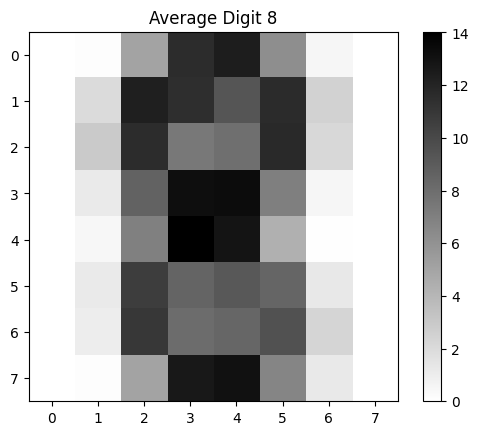

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Drop label column
X_8 = df_8.drop(columns=['digit']).values

# Compute mean image
mean_image = np.mean(X_8, axis=0).reshape(8, 8)

plt.imshow(mean_image, cmap=plt.cm.gray_r)
plt.title("Average Digit 8")
plt.colorbar()
plt.show()

This plot represents the average handwritten digit 8 computed by taking the mean pixel intensity at each position across all 174 samples of digit 8 and reshaping the result into an 8×8 image. Darker regions indicate pixels that consistently contain ink across different writing styles, while lighter regions correspond to areas that are rarely used. The visualization clearly reveals the defining structure of the digit 8, including the two loops and the central connection, while suppressing individual handwriting noise. This shows that most variation in digit 8 occurs around the loop boundaries rather than at the image edges, providing a strong justification for focusing subsequent analysis on structural features and dimensionality reduction techniques such as PCA.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets

# Load digits dataset
digits = datasets.load_digits()

# Full data
X = digits.data        # (n_samples, 64)
y = digits.target     # labels 0–9

# Subset digit 8
X_8 = X[y == 8]

print("X_8 shape:", X_8.shape)


X_8 shape: (174, 64)


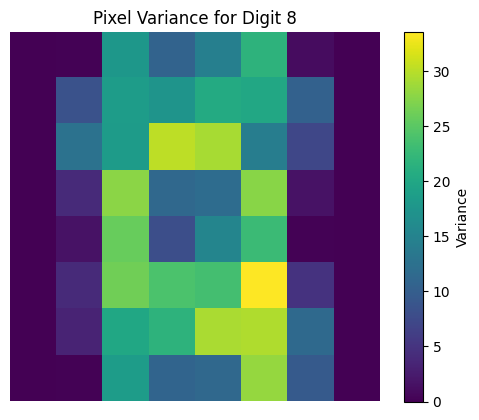

In [ ]:
variance_image = np.var(X_8, axis=0).reshape(8, 8)

plt.imshow(variance_image, cmap="viridis")
plt.title("Pixel Variance for Digit 8")
plt.colorbar(label="Variance")
plt.axis("off")
plt.show()


Brighter regions indicate pixels with higher variance, meaning those locations differ most between writers, while darker regions correspond to pixels that are consistently either filled or empty. The highest variance appears around the loop boundaries and the central connection between the two loops, suggesting that differences in stroke thickness, loop size, and how tightly the loops are connected are the main sources of variation within digit 8. In contrast, the outer corners show very low variance, confirming that these areas rarely contain ink and contribute little to distinguishing writing styles.

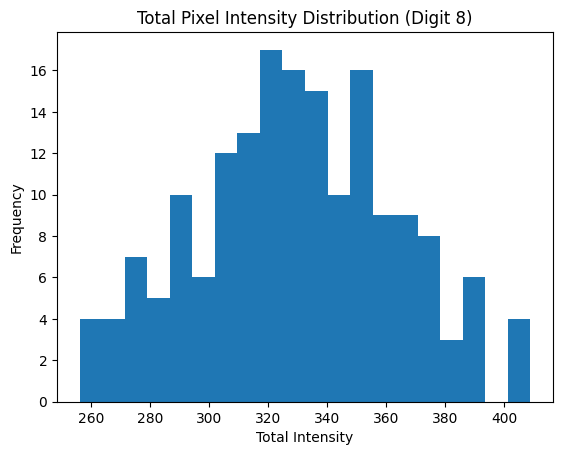

In [ ]:
total_intensity = np.sum(X_8, axis=1)

plt.hist(total_intensity, bins=20)
plt.title("Total Pixel Intensity Distribution (Digit 8)")
plt.xlabel("Total Intensity")
plt.ylabel("Frequency")
plt.show()

This histogram shows the distribution of total pixel intensity for all samples of digit 8, where total intensity represents the overall amount of ink used in each handwritten digit. The spread of values indicates substantial variation in stroke thickness and writing pressure, with some 8s appearing lighter and others much darker. The unimodal but wide distribution suggests that while most digit 8s share a common overall structure, writers differ significantly in how heavily they draw the digit.

#Feature thinking

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import datasets



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import datasets

# -----------------------------
# 1) Load digits + build DataFrame
# -----------------------------
digits = datasets.load_digits()

feature_names = [f"pixel_{i}" for i in range(digits.data.shape[1])]
df = pd.DataFrame(digits.data, columns=feature_names)
df["digit"] = digits.target

# -----------------------------
# 2) Filter to Digit 8 only (NO images variable needed)
# -----------------------------
df_8 = df[df["digit"] == 8].copy().reset_index(drop=True)

# Pixel matrix for digit 8 (n_samples x 64)
X8 = df_8.drop(columns=["digit"]).to_numpy()

# Reshape to (n_samples x 8 x 8) for region-based features
imgs8 = X8.reshape(-1, 8, 8)

# -----------------------------
# 3) Feature engineering for Digit 8
# -----------------------------
eps = 1e-9

# Half intensities
top_half = imgs8[:, :4, :].sum(axis=(1, 2))
bottom_half = imgs8[:, 4:, :].sum(axis=(1, 2))
left_half = imgs8[:, :, :4].sum(axis=(1, 2))
right_half = imgs8[:, :, 4:].sum(axis=(1, 2))

# Overall intensity and sparsity/thickness proxies
flat8 = imgs8.reshape(len(imgs8), -1)
total_intensity = flat8.sum(axis=1)
nonzero_count = (flat8 > 0).sum(axis=1)
avg_nonzero_intensity = total_intensity / (nonzero_count + eps)

# Digit-8 specific structure: center "pinch" where loops meet
center_band = imgs8[:, 3:5, :].sum(axis=(1, 2))

# Loop closure proxy: perimeter intensity (closed loops tend to darken outer boundary)
top_row = imgs8[:, 0, :].sum(axis=1)
bottom_row = imgs8[:, 7, :].sum(axis=1)
left_col = imgs8[:, :, 0].sum(axis=1)
right_col = imgs8[:, :, 7].sum(axis=1)
perimeter = top_row + bottom_row + left_col + right_col

# Symmetry measures
symmetry_abs = np.abs(left_half - right_half)
symmetry_ratio = symmetry_abs / (left_half + right_half + eps)

# Scale-invariant loop balance
loop_ratio = top_half / (bottom_half + eps)

# -----------------------------
# 4) Interaction Terms (ITs)
# -----------------------------
IT1_loop_balance = top_half - bottom_half
IT2_symmetry_abs = symmetry_abs
IT3_two_loop_strength = top_half * bottom_half
IT4_center_relative = center_band / (total_intensity + eps)
IT5_closure_relative = perimeter / (total_intensity + eps)
IT6_balanced_strong = (top_half * bottom_half) / (symmetry_abs + 1)

# -----------------------------
# 5) Build engineered-features DataFrame (Digit 8 only)
# -----------------------------
df_feat8 = pd.DataFrame({
    "top_half": top_half,
    "bottom_half": bottom_half,
    "left_half": left_half,
    "right_half": right_half,
    "total_intensity": total_intensity,
    "nonzero_count": nonzero_count,
    "avg_nonzero_intensity": avg_nonzero_intensity,
    "center_band": center_band,
    "perimeter": perimeter,
    "loop_ratio": loop_ratio,
    "symmetry_abs": symmetry_abs,
    "symmetry_ratio": symmetry_ratio,
    "IT1_loop_balance": IT1_loop_balance,
    "IT2_symmetry_abs": IT2_symmetry_abs,
    "IT3_two_loop_strength": IT3_two_loop_strength,
    "IT4_center_relative": IT4_center_relative,
    "IT5_closure_relative": IT5_closure_relative,
    "IT6_balanced_strong": IT6_balanced_strong
})

print("df_8 shape:", df_8.shape)          # original pixel df filtered to 8
print("df_feat8 shape:", df_feat8.shape)  # engineered feature table
print(df_feat8.head())

df_8 shape: (174, 65)
df_feat8 shape: (174, 18)
   top_half  bottom_half  left_half  right_half  total_intensity  \
0     169.0        188.0      178.0       179.0            357.0   
1     151.0        111.0      144.0       118.0            262.0   
2     155.0        157.0      167.0       145.0            312.0   
3     168.0        130.0      189.0       109.0            298.0   
4     170.0        168.0      178.0       160.0            338.0   

   nonzero_count  avg_nonzero_intensity  center_band  perimeter  loop_ratio  \
0             38               9.394737         85.0       86.0    0.898936   
1             30               8.733333         57.0       69.0    1.360360   
2             32               9.750000         85.0       55.0    0.987261   
3             33               9.030303         67.0       81.0    1.292308   
4             34               9.941176         74.0       79.0    1.011905   

   symmetry_abs  symmetry_ratio  IT1_loop_balance  IT2_symmetry_abs 

This output confirms that your feature engineering step successfully transformed the original digit-8 subset from 174 images with 64 raw pixel values into a more interpretable feature-based representation with 18 engineered features per image. The features capture meaningful structural properties of digit 8, including loop balance (top vs bottom halves), left–right symmetry, overall stroke intensity, stroke density (nonzero pixel count and average intensity), and central connectivity.

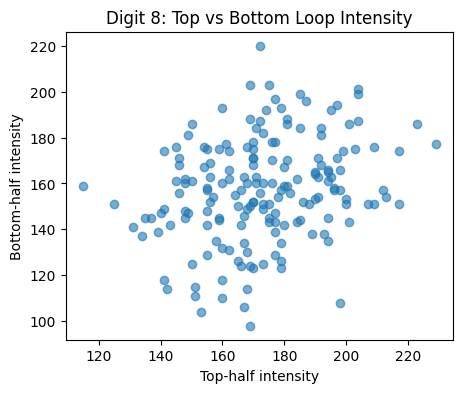

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5,4))
plt.scatter(top_half, bottom_half, alpha=0.6)
plt.xlabel("Top-half intensity")
plt.ylabel("Bottom-half intensity")
plt.title("Digit 8: Top vs Bottom Loop Intensity")
plt.show()

This scatter plot compares the total pixel intensity in the top half versus the bottom half of each handwritten digit 8, providing insight into how ink is distributed between the two loops. Most points cluster around a diagonal pattern, indicating that many digit 8s have relatively balanced top and bottom loops. However, the noticeable spread around this diagonal shows meaningful variation, with some writers emphasizing the top loop more heavily and others drawing a stronger bottom loop.

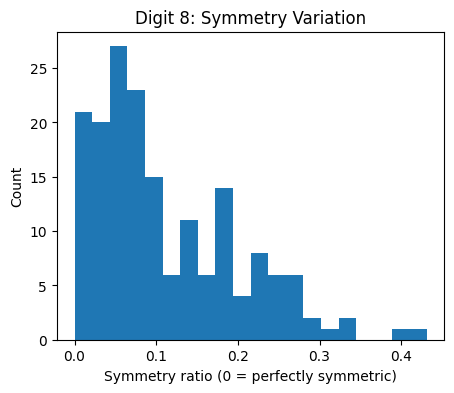

In [ ]:
plt.figure(figsize=(5,4))
plt.hist(symmetry_ratio, bins=20)
plt.xlabel("Symmetry ratio (0 = perfectly symmetric)")
plt.ylabel("Count")
plt.title("Digit 8: Symmetry Variation")
plt.show()

Most observations are concentrated near low symmetry ratios, confirming that digit 8 is generally written in a fairly symmetric manner. However, the long right tail indicates that a subset of samples exhibits noticeable asymmetry, likely due to tilted writing, uneven loop sizes, or irregular stroke placement. This variation demonstrates that symmetry is an informative feature for distinguishing handwriting styles within digit 8 and supports its inclusion in the engineered feature set and interaction terms.

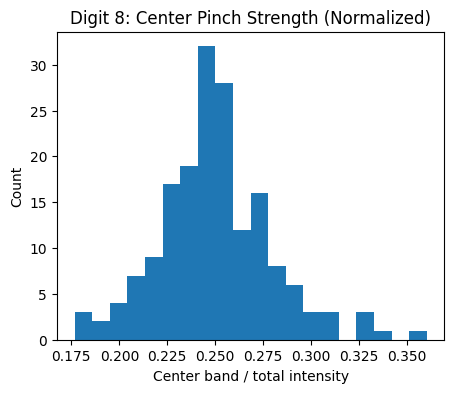

In [ ]:
plt.figure(figsize=(5,4))
plt.hist(IT4_center_relative, bins=20)
plt.xlabel("Center band / total intensity")
plt.ylabel("Count")
plt.title("Digit 8: Center Pinch Strength (Normalized)")
plt.show()

Most values cluster around a relatively narrow range, indicating that many writers connect the two loops of the digit 8 with a similar degree of central thickness. However, the spread and right tail of the distribution reveal meaningful variation, with some 8s exhibiting a much stronger or thicker central connection than others.

#PCA

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# X8 is your 174 x 64 pixel matrix
scaler = StandardScaler()
X8_scaled = scaler.fit_transform(X8)


In [ ]:
pca = PCA()
X8_pca = pca.fit_transform(X8_scaled)

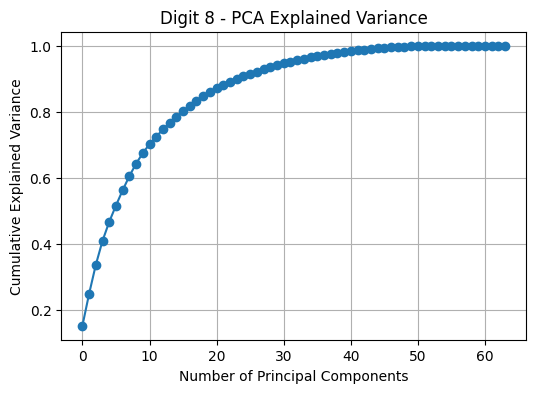

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

explained_var = pca.explained_variance_ratio_
cum_var = np.cumsum(explained_var)

plt.figure(figsize=(6,4))
plt.plot(cum_var, marker='o')
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Digit 8 - PCA Explained Variance")
plt.grid()
plt.show()

This plot shows how much information about the handwritten digit 8 is captured as we include more principal components. The sharp increase at the beginning means that the first few components already explain most of the important differences in how people write an 8. As more components are added, the curve gradually levels off, indicating that additional components contribute less new information and mainly capture small details or noise.

##PC1

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Standardize
scaler = StandardScaler()
X8_scaled = scaler.fit_transform(X8)

# Fit PCA
pca = PCA()
pca.fit(X8_scaled)

PCA()

In [ ]:
pc1 = pca.components_[0]


In [ ]:
pc1_image = pc1.reshape(8, 8)


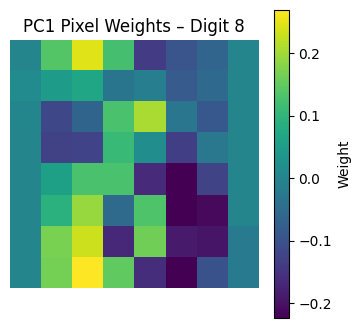

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Load digits dataset
digits = datasets.load_digits()
X = digits.data
y = digits.target

# Subset digit 8
X_8 = X[y == 8]

# Standardize data
scaler = StandardScaler()
X_8_scaled = scaler.fit_transform(X_8)

# PCA
pca = PCA()
pca.fit(X_8_scaled)

# Extract PC1 and reshape to 8x8
pc1_image = pca.components_[0].reshape(8, 8)

# Plot PC1 pixel weights
plt.figure(figsize=(4,4))
plt.imshow(pc1_image, cmap="viridis")
plt.colorbar(label="Weight")
plt.title("PC1 Pixel Weights – Digit 8")
plt.axis("off")
plt.show()


This visualization shows the pixel weights of the first principal component (PC1) for digit 8, reshaped back into the original 8×8 image layout. Brighter colors represent pixels that contribute more strongly to the main pattern of variation among handwritten 8s, while darker colors indicate pixels that contribute in the opposite direction. The strongest weights appear around the central region and loop areas, suggesting that differences in how writers shape and connect the two loops, such as stroke thickness and balance are the most important factors captured by PC1.

##PC2

In [ ]:
pc2 = pca.components_[1]

In [ ]:
pc2_image = pc2.reshape(8, 8)

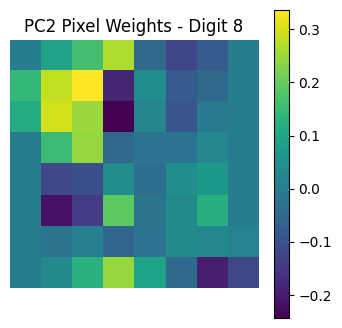

In [ ]:
plt.figure(figsize=(4,4))
plt.imshow(pc2_image, cmap="viridis")
plt.colorbar()
plt.title("PC2 Pixel Weights - Digit 8")
plt.axis("off")
plt.show()

The second principal component (PC2) shows another major way handwritten 8s vary beyond the main overall shape captured by PC1. Based on the heatmap, the strongest positive weights appear around the upper loop of the digit. This suggests that PC2 is mainly capturing differences in how people draw the top portion of the 8, such as whether the loop is thicker, rounder, or more narrow.
There are also negative weights in some lower and side areas of the digit. This indicates that when the top loop becomes stronger or more emphasized, the bottom loop or surrounding areas sometimes become less intense. This shows that people often balance the two loops differently when writing the number 8.
Overall, PC2 helps explain stylistic differences in how the upper and lower loops of the digit are formed. This helps show that even within the same digit, there are multiple handwriting variations.

In [ ]:
X8_pca = pca.transform(X8_scaled)

pc1_scores = X8_pca[:, 0]
pc2_scores = X8_pca[:, 1]

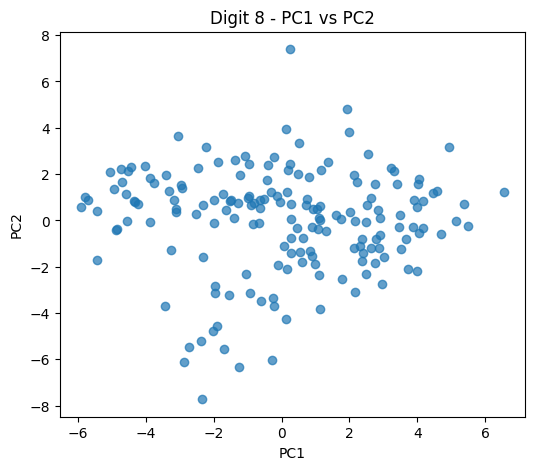

In [ ]:
plt.figure(figsize=(6,5))
plt.scatter(pc1_scores, pc2_scores, alpha=0.7)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Digit 8 - PC1 vs PC2")
plt.show()
